# A Tour of Classification Models — Credit Risk Edition (American Express Default Prediction)

Third of three credit-risk notebooks: **Logistic Regression → L2/L1/Elastic-Net
Logistic → MLP → Random Forest → XGBoost → CatBoost → LightGBM**, each tuned via
`RandomizedSearchCV` with a compact parameter search.

**Dataset:** [American Express — Default Prediction](https://www.kaggle.com/competitions/amex-default-prediction)
(Kaggle competition) — predicting whether a credit card customer defaults, from
**anonymized monthly account statements** (190 features: `D_*` delinquency,
`S_*` spend, `P_*` payment, `B_*` balance, `R_*` risk variables).

**A real scale problem, handled transparently:** the official training data is
**16.4 GB** (5.5 million statement-rows for ~459,000 customers) — several orders
of magnitude past what a teaching notebook should load wholesale. We use a
community-published **1% customer sample** (`alperenprdox/amex-banking-dataset-1-fraction`
on Kaggle) instead of the full file — 4,589 customers, same schema, same class
balance, a fraction of the compute.

**What's structurally new here vs. the previous two credit notebooks:** this data
is **longitudinal** — each customer has up to 13 monthly statements, not one row
per applicant. Home Credit and Give Me Some Credit both start as one-row-per-
applicant; this dataset doesn't, and needs an explicit aggregation decision before
it can go through the same per-row classification pipeline at all.


## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, accuracy_score, precision_score,
                              recall_score, f1_score, log_loss, roc_curve,
                              confusion_matrix)


from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)


Matplotlib is building the font cache; this may take a moment.


Searches use two candidates and two cross-validation folds. Every selected model refits on the complete training partition.

## 2. Load, aggregate, and clean the data

`train_data_1pct.csv` has one row per customer **per statement month** — before
any of the previous notebooks' per-row classifiers can apply, we need **one row
per customer**. We take each customer's **most recent statement** (`S_2` is the
statement date) — the simplest standard baseline for this competition, and
usually a strong one, since a customer's most recent financial snapshot carries
most of the predictive signal a full history would.


In [2]:
raw = pd.read_csv("amex_train_data_1pct.csv", parse_dates=["S_2"])
labels = pd.read_csv("amex_train_labels_1pct.csv")

print(f"Raw statement-rows: {raw.shape}, unique customers: {raw['customer_ID'].nunique()}")
print(f"Statements per customer: min={raw.groupby('customer_ID').size().min()}, "
      f"max={raw.groupby('customer_ID').size().max()}, "
      f"mean={raw.groupby('customer_ID').size().mean():.1f}")

last_statement = raw.sort_values("S_2").groupby("customer_ID", as_index=False).last()
df = last_statement.merge(labels, on="customer_ID", how="inner")
print(f"\nAfter aggregating to one row per customer and joining labels: {df.shape}")


Raw statement-rows: (55249, 190), unique customers: 4589
Statements per customer: min=1, max=13, mean=12.0

After aggregating to one row per customer and joining labels: (4589, 191)


/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98039/1429206103.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  last_statement = raw.sort_values("S_2").groupby("customer_ID", as_index=False).last()


In [3]:
miss_frac = df.isna().mean()
drop_cols = miss_frac[miss_frac > 0.5].index.tolist()
df = df.drop(columns=drop_cols)
print(f"Dropped {len(drop_cols)} columns more than 50% missing (post-aggregation).")

df = df.drop(columns=["customer_ID", "S_2"])

categorical_features = ["D_63", "D_64"]
numeric_features = [c for c in df.columns if c not in categorical_features + ["target"]]

for c in numeric_features:
    df[c] = df[c].fillna(df[c].median())
for c in categorical_features:
    df[c] = df[c].fillna("Missing")

print(f"Final shape: {df.shape}  ({len(numeric_features)} numeric, {len(categorical_features)} categorical features)")

X = df[numeric_features + categorical_features]
y = df["target"]
print(f"\nClass balance: {y.value_counts(normalize=True).to_dict()}")

print(X.head())
print(y.head())


Dropped 26 columns more than 50% missing (post-aggregation).
Final shape: (4589, 163)  (160 numeric, 2 categorical features)

Class balance: {0: 0.7537589888864676, 1: 0.24624101111353236}
        P_2      D_39       B_1       B_2       R_1       S_3      D_41  \
0  0.681824  0.035275  0.232731  0.082090  0.000366  0.282680  0.005512   
1  0.896965  0.002729  0.004943  0.812372  0.004379  0.166949  0.004109   
2  0.685784  0.007922  0.046566  0.816970  0.503407  0.595819  0.009310   
3  0.716210  0.033712  0.008362  0.814635  0.009841  0.171215  0.005994   
4  0.880845  0.006248  0.095200  0.238735  0.005351  0.106537  0.002903   

        B_3      D_43      D_44  ...     D_133      R_28     D_139     D_140  \
0  0.105355  0.080219  0.001312  ...  0.008797  0.000318  1.003707  1.003664   
1  0.007626  0.057046  0.002546  ...  0.003705  0.004415  0.004716  0.002471   
2  0.007427  0.080219  0.008113  ...  0.000174  0.000586  0.002516  0.008102   
3  0.002301  0.080219  0.000631  ...  0.

### Quick EDA

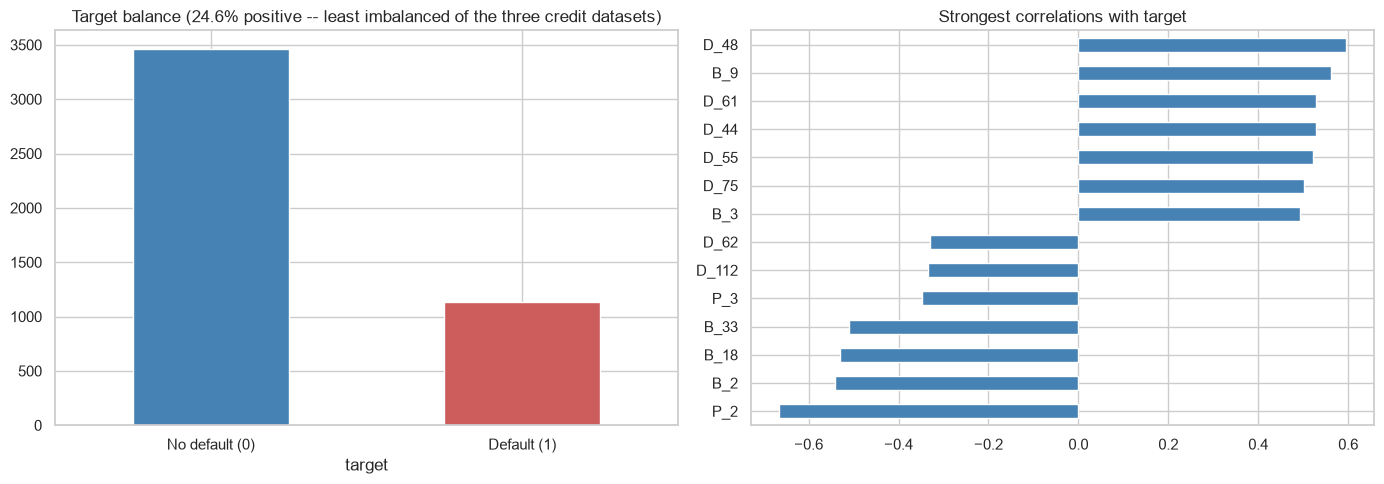

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

y.value_counts().plot(kind="bar", ax=axes[0], color=["steelblue", "indianred"])
axes[0].set_title(f"Target balance ({y.mean():.1%} positive -- least imbalanced of the three credit datasets)")
axes[0].set_xticklabels(["No default (0)", "Default (1)"], rotation=0)

top_corr = df[numeric_features + ["target"]].corr(numeric_only=True)["target"].drop("target")
top_corr = pd.concat([top_corr.nsmallest(7), top_corr.nlargest(7)]).sort_values()
top_corr.plot(kind="barh", ax=axes[1], color="steelblue")
axes[1].set_title("Strongest correlations with target")

plt.tight_layout()
plt.show()


At ~24.6% positive, this is the **least imbalanced** of the three credit
datasets (vs. 6.7% for Give Me Some Credit, 8.1% for Home Credit) — ROC-AUC still
applies the same way, but accuracy is a somewhat less misleading baseline here
than on the other two. `P_2` (an anonymized "payment" variable) dominates the
correlation ranking, consistent with this being widely reported as the single
strongest feature in the actual competition.


## 3. Train / test split and preprocessing

Same pattern as Home Credit: two-track `ColumnTransformer` (scaled+encoded for
Logistic Regression/MLP; unscaled+encoded for Random Forest/XGBoost/LightGBM;
raw + `cat_features` for CatBoost), stratified split and CV throughout.


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

preprocess_scaled = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])
X_train_scaled = preprocess_scaled.fit_transform(X_train)
X_test_scaled = preprocess_scaled.transform(X_test)
scaled_feature_names = preprocess_scaled.get_feature_names_out()

preprocess_tree = ColumnTransformer([
    ("num", "passthrough", numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])
X_train_enc = preprocess_tree.fit_transform(X_train)
X_test_enc = preprocess_tree.transform(X_test)
tree_feature_names = preprocess_tree.get_feature_names_out()

cat_feature_idx = [X_train.columns.get_loc(c) for c in categorical_features]

skf = StratifiedKFold(n_splits=2, shuffle=True, random_state=RANDOM_STATE)
skf3 = StratifiedKFold(n_splits=2, shuffle=True, random_state=RANDOM_STATE)

print(f"Train: {X_train.shape} ({y_train.mean():.2%} positive)")
print(f"Test:  {X_test.shape} ({y_test.mean():.2%} positive)")


Train: (3671, 162) (24.63% positive)
Test:  (918, 162) (24.62% positive)


In [6]:
results = {}

def evaluate(name, y_true, y_pred_proba, threshold=0.5):
    y_pred = (y_pred_proba >= threshold).astype(int)
    metrics = {
        "ROC_AUC": roc_auc_score(y_true, y_pred_proba),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "LogLoss": log_loss(y_true, y_pred_proba),
    }
    results[name] = metrics
    print(f"{name:20s}  ROC_AUC={metrics['ROC_AUC']:.4f}  F1={metrics['F1']:.4f}  "
          f"Precision={metrics['Precision']:.4f}  Recall={metrics['Recall']:.4f}")
    return metrics


## 4. Logistic Regression


In [7]:
log_reg = LogisticRegression(C=np.inf, max_iter=2000, random_state=RANDOM_STATE)
log_reg.fit(X_train_scaled, y_train)
y_proba_lr = log_reg.predict_proba(X_test_scaled)[:, 1]
evaluate("LogisticRegression", y_test, y_proba_lr)


LogisticRegression    ROC_AUC=0.9421  F1=0.7778  Precision=0.8155  Recall=0.7434


{'ROC_AUC': 0.9420558596347639,
 'Accuracy': 0.8954248366013072,
 'Precision': 0.8155339805825242,
 'Recall': 0.7433628318584071,
 'F1': 0.7777777777777778,
 'LogLoss': 0.27210948931200873}

/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98039/628306305.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=coef_df, x="coefficient", y="feature", palette="viridis")


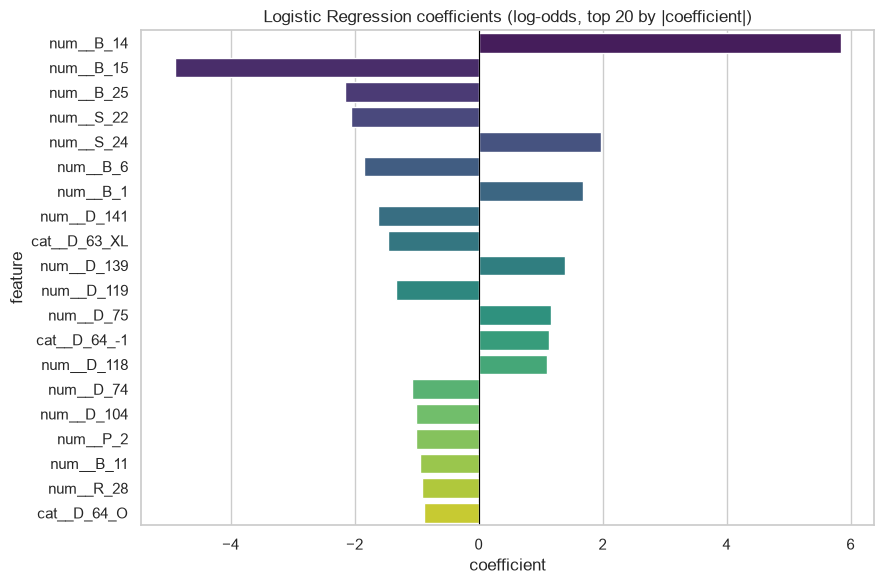

,feature,coefficient
40,num__B_14,5.841665
44,num__B_15,-4.901473
71,num__B_25,-2.155747
114,num__S_22,-2.051741
116,num__S_24,1.973910
17,num__B_6,-1.852893
2,num__B_1,1.692087
156,num__D_141,-1.616205
163,cat__D_63_XL,-1.463252
154,num__D_139,1.386717


In [8]:
coef_df = pd.DataFrame({"feature": scaled_feature_names, "coefficient": log_reg.coef_[0]}
                       ).sort_values("coefficient", key=abs, ascending=False).head(20)
plt.figure(figsize=(9, 6))
sns.barplot(data=coef_df, x="coefficient", y="feature", palette="viridis")
plt.title("Logistic Regression coefficients (log-odds, top 20 by |coefficient|)")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()
coef_df


## 5. Regularized Logistic Regression: L2, L1 & Elastic Net


In [9]:
Cs = [0.01, 1.0, 100.0]

l2_logreg = LogisticRegressionCV(
    Cs=Cs, l1_ratios=[0.0], use_legacy_attributes=False, solver="lbfgs", cv=skf3, scoring="roc_auc",
    max_iter=2000, n_jobs=2, random_state=RANDOM_STATE, tol=1e-2,
)
l2_logreg.fit(X_train_scaled, y_train)
y_proba_l2 = l2_logreg.predict_proba(X_test_scaled)[:, 1]
evaluate("LogReg (L2)", y_test, y_proba_l2)
print(f"Chosen C: {l2_logreg.C_:.4f}")


LogReg (L2)           ROC_AUC=0.9608  F1=0.7991  Precision=0.8357  Recall=0.7655
Chosen C: 0.0100


In [10]:
l1_logreg = LogisticRegressionCV(
    Cs=Cs, l1_ratios=[1.0], use_legacy_attributes=False, solver="saga", cv=skf3, scoring="roc_auc",
    max_iter=2000, tol=1e-3, n_jobs=2, random_state=RANDOM_STATE,
)
l1_logreg.fit(X_train_scaled, y_train)
y_proba_l1 = l1_logreg.predict_proba(X_test_scaled)[:, 1]
evaluate("LogReg (L1)", y_test, y_proba_l1)
print(f"Chosen C: {l1_logreg.C_:.4f}")
print(f"Features zeroed out: {(l1_logreg.coef_[0] == 0).sum()} / {len(scaled_feature_names)}")


LogReg (L1)           ROC_AUC=0.9537  F1=0.7907  Precision=0.8333  Recall=0.7522
Chosen C: 1.0000
Features zeroed out: 8 / 171


In [11]:
elastic_logreg = LogisticRegressionCV(
    Cs=Cs, use_legacy_attributes=False, solver="saga",
    l1_ratios=[.5], cv=skf3, scoring="roc_auc",
    max_iter=2000, tol=1e-3, n_jobs=2, random_state=RANDOM_STATE,
)
elastic_logreg.fit(X_train_scaled, y_train)
y_proba_elastic = elastic_logreg.predict_proba(X_test_scaled)[:, 1]
evaluate("LogReg (ElasticNet)", y_test, y_proba_elastic)
print(f"Chosen C: {elastic_logreg.C_:.4f}, l1_ratio: {elastic_logreg.l1_ratio_:.2f}")


LogReg (ElasticNet)   ROC_AUC=0.9569  F1=0.7916  Precision=0.8408  Recall=0.7478
Chosen C: 0.0100, l1_ratio: 0.50


With ~170+ genuinely anonymized numeric features (many likely redundant —
several `D_*`/`B_*`/`S_*` columns are widely suspected to be correlated
transformations of similar underlying account signals), this is the dataset in
the series where L1/Elastic Net's feature-selection role is most clearly useful.


## 6. K-Nearest Neighbors (KNN)

A genuinely different kind of model from everything else in this notebook: KNN
has no coefficients and builds no trees. It predicts a point's class
probability from the (optionally distance-weighted) vote of its `k` nearest
training points in feature space — "nearest" measured on the *scaled* features
(the same `X_train_scaled`/`X_test_scaled` used by the logistic regression
variants and MLP above), since distance is meaningless once features sit on
wildly different raw scales.

**When to reach for it:** a quick, assumption-light baseline — no linearity, no
tree-splittable structure, nothing learned at "training" time (there's no
training at all; `.fit()` just stores the data).

**Key hyperparameters:**
- `n_neighbors` (k): more neighbors → smoother, more biased predictions; fewer →
  noisier, more variance.
- `weights`: `"uniform"` averages neighbors equally; `"distance"` weights closer
  neighbors more heavily.
- `p`: the distance metric's power — `1` = Manhattan, `2` = Euclidean.

**Limitations:** prediction is slow on large datasets (every query compares
against the full training set); accuracy degrades in high dimensions (the
"curse of dimensionality" — with enough dimensions, every point ends up roughly
equidistant from every other).


In [12]:
knn = KNeighborsClassifier(n_neighbors=15, weights="distance")
knn.fit(X_train_scaled, y_train)

y_proba_knn = knn.predict_proba(X_test_scaled)[:, 1]
evaluate("KNN", y_test, y_proba_knn)


KNN                   ROC_AUC=0.9428  F1=0.7000  Precision=0.8636  Recall=0.5885


{'ROC_AUC': 0.9428231623100924,
 'Accuracy': 0.8758169934640523,
 'Precision': 0.8636363636363636,
 'Recall': 0.588495575221239,
 'F1': 0.7,
 'LogLoss': 0.4032710976452569}

### Hyperparameter tuning with `GridSearchCV`

Fit the search on the training data and compare the selected model on the held-out partition.

In [13]:
knn_param_grid = {'n_neighbors': [5, 15], 'weights': ['distance'], 'p': [2]}


knn_grid = GridSearchCV(
    KNeighborsClassifier(),
    param_grid=knn_param_grid,
    cv=skf3,
    scoring="roc_auc",
    n_jobs=2,
)
knn_grid.fit(X_train_scaled, y_train)

print(f"Best params: {knn_grid.best_params_}")
print(f"Best CV ROC-AUC: {knn_grid.best_score_:.4f}")


Best params: {'n_neighbors': 15, 'p': 2, 'weights': 'distance'}
Best CV ROC-AUC: 0.9195


In [14]:
y_proba_knn_tuned = knn_grid.best_estimator_.predict_proba(X_test_scaled)[:, 1]
evaluate("KNN (tuned)", y_test, y_proba_knn_tuned)


KNN (tuned)           ROC_AUC=0.9428  F1=0.7000  Precision=0.8636  Recall=0.5885


{'ROC_AUC': 0.9428231623100924,
 'Accuracy': 0.8758169934640523,
 'Precision': 0.8636363636363636,
 'Recall': 0.588495575221239,
 'F1': 0.7,
 'LogLoss': 0.4032710976452569}

## 7. MLP (Multi-Layer Perceptron)


In [15]:
mlp = MLPClassifier(hidden_layer_sizes=(64, 32), activation="relu", alpha=1e-4,
                     learning_rate_init=1e-3, max_iter=500, early_stopping=True,
                     n_iter_no_change=15, random_state=RANDOM_STATE)
mlp.fit(X_train_scaled, y_train)
y_proba_mlp = mlp.predict_proba(X_test_scaled)[:, 1]
evaluate("MLP", y_test, y_proba_mlp)


MLP                   ROC_AUC=0.9513  F1=0.7936  Precision=0.8238  Recall=0.7655


{'ROC_AUC': 0.9512954626835132,
 'Accuracy': 0.9019607843137255,
 'Precision': 0.8238095238095238,
 'Recall': 0.7654867256637168,
 'F1': 0.7935779816513762,
 'LogLoss': 0.24569114276660797}

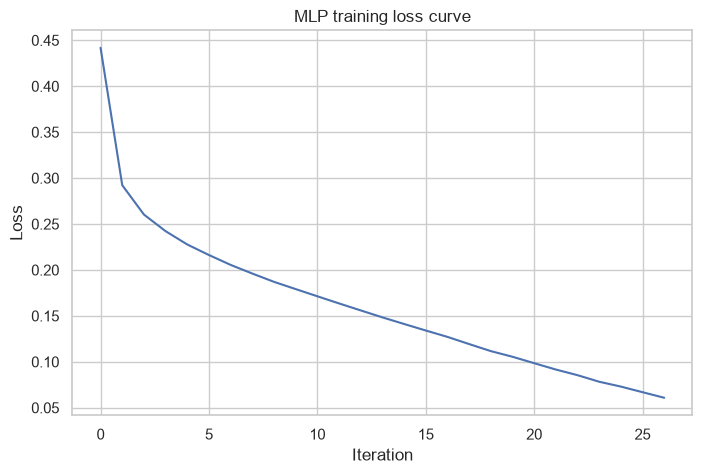

In [16]:
plt.plot(mlp.loss_curve_)
plt.title("MLP training loss curve")
plt.xlabel("Iteration"); plt.ylabel("Loss")
plt.show()


### Hyperparameter tuning with `RandomizedSearchCV`

Fit the search on the training data and compare the selected model on the held-out partition.

In [17]:
mlp_param_dist = {'hidden_layer_sizes': [(64, 32)], 'alpha': [0.0001, 0.001]}


mlp_search = RandomizedSearchCV(
    MLPClassifier(activation="relu", learning_rate_init=1e-3, max_iter=500,
                  early_stopping=True, n_iter_no_change=15, random_state=RANDOM_STATE),
    param_distributions=mlp_param_dist, n_iter=2, cv=skf3, scoring="roc_auc",
    n_jobs=2, random_state=RANDOM_STATE,
)
mlp_search.fit(X_train_scaled, y_train)
print(f"Best params: {mlp_search.best_params_}")
print(f"Best CV ROC-AUC: {mlp_search.best_score_:.4f}")


Best params: {'hidden_layer_sizes': (64, 32), 'alpha': 0.001}
Best CV ROC-AUC: 0.9341


In [18]:
y_proba_mlp_tuned = mlp_search.best_estimator_.predict_proba(X_test_scaled)[:, 1]
evaluate("MLP (tuned)", y_test, y_proba_mlp_tuned)


MLP (tuned)           ROC_AUC=0.9513  F1=0.7963  Precision=0.8246  Recall=0.7699


{'ROC_AUC': 0.9512507033607858,
 'Accuracy': 0.9030501089324618,
 'Precision': 0.8246445497630331,
 'Recall': 0.7699115044247787,
 'F1': 0.7963386727688787,
 'LogLoss': 0.2456155000259258}

## 8. Random Forest


In [19]:
rf = RandomForestClassifier(n_estimators=300, max_depth=None, min_samples_leaf=2,
                             n_jobs=2, random_state=RANDOM_STATE)
rf.fit(X_train_enc, y_train)
y_proba_rf = rf.predict_proba(X_test_enc)[:, 1]
evaluate("RandomForest", y_test, y_proba_rf)


RandomForest          ROC_AUC=0.9627  F1=0.8100  Precision=0.8287  Recall=0.7920


{'ROC_AUC': 0.9627058928845464,
 'Accuracy': 0.9084967320261438,
 'Precision': 0.8287037037037037,
 'Recall': 0.7920353982300885,
 'F1': 0.8099547511312217,
 'LogLoss': 0.23927156733268878}

/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98039/3683593754.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=rf_importance, x="importance", y="feature", palette="viridis")


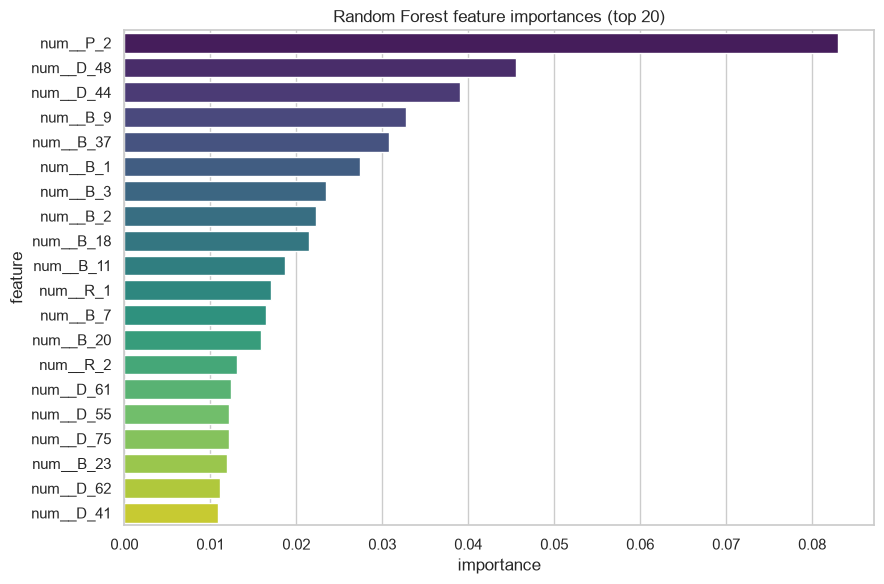

,feature,importance
0,num__P_2,0.083042
16,num__D_48,0.045527
9,num__D_44,0.039042
21,num__B_9,0.032801
125,num__B_37,0.030818
2,num__B_1,0.027384
7,num__B_3,0.023506
3,num__B_2,0.022342
50,num__B_18,0.021458
27,num__B_11,0.018655


In [20]:
rf_importance = pd.DataFrame({"feature": tree_feature_names, "importance": rf.feature_importances_}
                             ).sort_values("importance", ascending=False).head(20)
plt.figure(figsize=(9, 6))
sns.barplot(data=rf_importance, x="importance", y="feature", palette="viridis")
plt.title("Random Forest feature importances (top 20)")
plt.tight_layout()
plt.show()
rf_importance


### Hyperparameter tuning with `RandomizedSearchCV`

Fit the search on the training data and compare the selected model on the held-out partition.

In [21]:
rf_param_dist = {'n_estimators': [300], 'max_depth': [8, 12], 'min_samples_leaf': [2, 5]}


rf_search = RandomizedSearchCV(
    RandomForestClassifier(n_jobs=2, random_state=RANDOM_STATE),
    param_distributions=rf_param_dist, n_iter=2, cv=skf3, scoring="roc_auc",
    n_jobs=2, random_state=RANDOM_STATE,
)
rf_search.fit(X_train_enc, y_train)
print(f"Best params: {rf_search.best_params_}")
print(f"Best CV ROC-AUC: {rf_search.best_score_:.4f}")


Best params: {'n_estimators': 300, 'min_samples_leaf': 5, 'max_depth': 8}
Best CV ROC-AUC: 0.9398


In [22]:
y_proba_rf_tuned = rf_search.best_estimator_.predict_proba(X_test_enc)[:, 1]
evaluate("RandomForest (tuned)", y_test, y_proba_rf_tuned)


RandomForest (tuned)  ROC_AUC=0.9623  F1=0.8126  Precision=0.8295  Recall=0.7965


{'ROC_AUC': 0.9622934676965573,
 'Accuracy': 0.9095860566448801,
 'Precision': 0.8294930875576036,
 'Recall': 0.7964601769911505,
 'F1': 0.8126410835214447,
 'LogLoss': 0.24061838621887505}

## 9. XGBoost (Extreme Gradient Boosting)


In [23]:
xgb = XGBClassifier(n_estimators=500, learning_rate=0.05, max_depth=5,
                    subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
                    eval_metric="auc", random_state=RANDOM_STATE, n_jobs=2)
xgb.fit(X_train_enc, y_train, eval_set=[(X_test_enc, y_test)], verbose=False)
y_proba_xgb = xgb.predict_proba(X_test_enc)[:, 1]
evaluate("XGBoost", y_test, y_proba_xgb)


XGBoost               ROC_AUC=0.9581  F1=0.7882  Precision=0.8122  Recall=0.7655


{'ROC_AUC': 0.9581180623049772,
 'Accuracy': 0.8986928104575164,
 'Precision': 0.812206572769953,
 'Recall': 0.7654867256637168,
 'F1': 0.7881548974943052,
 'LogLoss': 0.24457305669784546}

/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98039/3336586695.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=xgb_importance, x="importance", y="feature", palette="viridis")


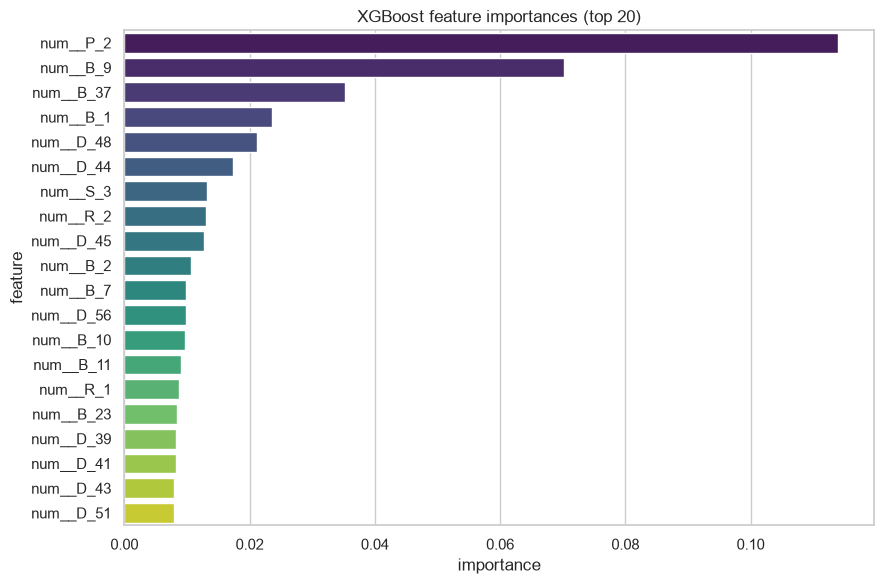

,feature,importance
0,num__P_2,0.114002
21,num__B_9,0.070132
125,num__B_37,0.035222
2,num__B_1,0.023603
16,num__D_48,0.021219
9,num__D_44,0.017410
5,num__S_3,0.013117
13,num__R_2,0.013066
11,num__D_45,0.012783
3,num__B_2,0.010563


In [24]:
xgb_importance = pd.DataFrame({"feature": tree_feature_names, "importance": xgb.feature_importances_}
                              ).sort_values("importance", ascending=False).head(20)
plt.figure(figsize=(9, 6))
sns.barplot(data=xgb_importance, x="importance", y="feature", palette="viridis")
plt.title("XGBoost feature importances (top 20)")
plt.tight_layout()
plt.show()
xgb_importance


### Hyperparameter tuning with `RandomizedSearchCV`

Fit the search on the training data and compare the selected model on the held-out partition.

In [25]:
xgb_param_dist = {'n_estimators': [500], 'max_depth': [3, 5], 'learning_rate': [0.03, 0.05]}


xgb_search = RandomizedSearchCV(
    XGBClassifier(subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
                  eval_metric="auc", random_state=RANDOM_STATE, n_jobs=2),
    param_distributions=xgb_param_dist, n_iter=2, cv=skf3, scoring="roc_auc",
    n_jobs=2, random_state=RANDOM_STATE,
)
xgb_search.fit(X_train_enc, y_train)
print(f"Best params: {xgb_search.best_params_}")
print(f"Best CV ROC-AUC: {xgb_search.best_score_:.4f}")


Best params: {'n_estimators': 500, 'max_depth': 5, 'learning_rate': 0.03}
Best CV ROC-AUC: 0.9399


In [26]:
y_proba_xgb_tuned = xgb_search.best_estimator_.predict_proba(X_test_enc)[:, 1]
evaluate("XGBoost (tuned)", y_test, y_proba_xgb_tuned)


XGBoost (tuned)       ROC_AUC=0.9590  F1=0.7973  Precision=0.8119  Recall=0.7832


{'ROC_AUC': 0.9590068545705662,
 'Accuracy': 0.9019607843137255,
 'Precision': 0.8119266055045872,
 'Recall': 0.7831858407079646,
 'F1': 0.7972972972972973,
 'LogLoss': 0.22726324200630188}

## 10. CatBoost (Categorical Boosting)

`D_63`/`D_64`, the two real categorical columns in this dataset, passed raw via
`cat_features` (at `.fit()` time, not the constructor).


In [27]:
cat = CatBoostClassifier(iterations=500, learning_rate=0.05, depth=6, l2_leaf_reg=3.0, cat_features=cat_feature_idx, random_seed=RANDOM_STATE, verbose=False, thread_count=2, allow_writing_files=False)
cat.fit(X_train, y_train, eval_set=(X_test, y_test), use_best_model=True)
y_proba_cat = cat.predict_proba(X_test)[:, 1]
evaluate("CatBoost", y_test, y_proba_cat)


CatBoost              ROC_AUC=0.9623  F1=0.8151  Precision=0.8206  Recall=0.8097


{'ROC_AUC': 0.9622934676965574,
 'Accuracy': 0.9095860566448801,
 'Precision': 0.820627802690583,
 'Recall': 0.8097345132743363,
 'F1': 0.8151447661469933,
 'LogLoss': 0.2160584743020264}

/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98039/2342986427.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cat_importance, x="importance", y="feature", palette="viridis")


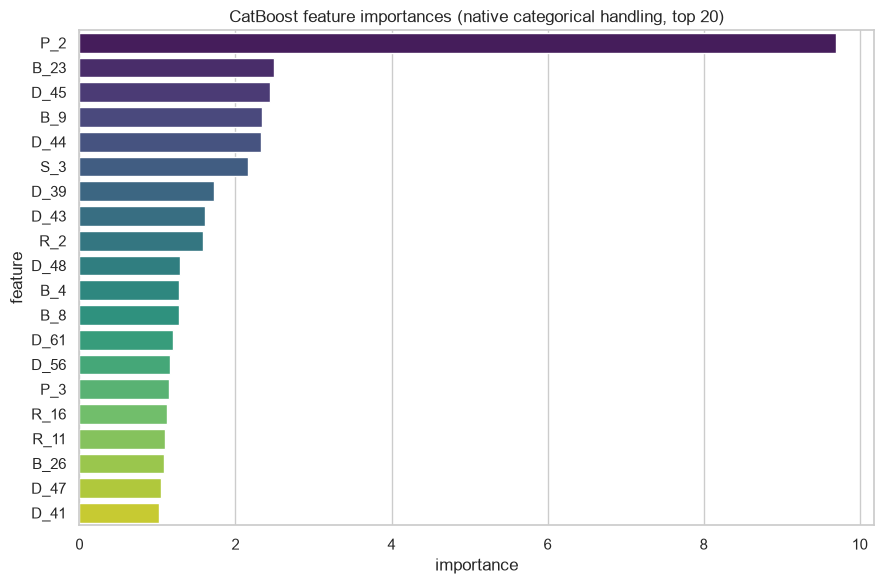

,feature,importance
0,P_2,9.698469
64,B_23,2.491911
11,D_45,2.440176
21,B_9,2.340148
9,D_44,2.326704
5,S_3,2.158327
1,D_39,1.723067
8,D_43,1.611868
13,R_2,1.578154
16,D_48,1.289461


In [28]:
cat_importance = pd.DataFrame({"feature": X_train.columns, "importance": cat.get_feature_importance()}
                               ).sort_values("importance", ascending=False).head(20)
plt.figure(figsize=(9, 6))
sns.barplot(data=cat_importance, x="importance", y="feature", palette="viridis")
plt.title("CatBoost feature importances (native categorical handling, top 20)")
plt.tight_layout()
plt.show()
cat_importance


### Hyperparameter tuning with `RandomizedSearchCV`

Fit the search on the training data and compare the selected model on the held-out partition.

In [29]:
cat_param_dist = {'iterations': [500], 'depth': [4, 6], 'learning_rate': [0.03, 0.05]}


cat_search = RandomizedSearchCV(
    CatBoostClassifier(l2_leaf_reg=3.0, random_seed=RANDOM_STATE, thread_count=1, allow_writing_files=False, verbose=False),
    param_distributions=cat_param_dist, n_iter=2, cv=skf3, scoring="roc_auc",
    n_jobs=2, random_state=RANDOM_STATE,
)
cat_search.fit(X_train, y_train, cat_features=cat_feature_idx)
print(f"Best params: {cat_search.best_params_}")
print(f"Best CV ROC-AUC: {cat_search.best_score_:.4f}")


Best params: {'learning_rate': 0.05, 'iterations': 500, 'depth': 4}
Best CV ROC-AUC: 0.9417


In [30]:
y_proba_cat_tuned = cat_search.best_estimator_.predict_proba(X_test)[:, 1]
evaluate("CatBoost (tuned)", y_test, y_proba_cat_tuned)


CatBoost (tuned)      ROC_AUC=0.9587  F1=0.7846  Precision=0.8047  Recall=0.7655


{'ROC_AUC': 0.9586807509335518,
 'Accuracy': 0.8965141612200436,
 'Precision': 0.8046511627906977,
 'Recall': 0.7654867256637168,
 'F1': 0.7845804988662132,
 'LogLoss': 0.22594194255062694}

## 11. LightGBM (Light Gradient Boosting Machine)


In [31]:
lgbm = LGBMClassifier(n_estimators=500, learning_rate=0.05, num_leaves=31,
                       min_child_samples=20, subsample=0.8, colsample_bytree=0.8,
                       random_state=RANDOM_STATE, n_jobs=2, verbose=-1)
lgbm.fit(X_train_enc, y_train, eval_set=[(X_test_enc, y_test)])
y_proba_lgbm = lgbm.predict_proba(X_test_enc)[:, 1]
evaluate("LightGBM", y_test, y_proba_lgbm)


LightGBM              ROC_AUC=0.9582  F1=0.7836  Precision=0.8075  Recall=0.7611


/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


{'ROC_AUC': 0.9581564274387436,
 'Accuracy': 0.8965141612200436,
 'Precision': 0.8075117370892019,
 'Recall': 0.7610619469026548,
 'F1': 0.7835990888382688,
 'LogLoss': 0.3360604026079515}

/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98039/4290498733.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=lgbm_importance, x="importance", y="feature", palette="viridis")


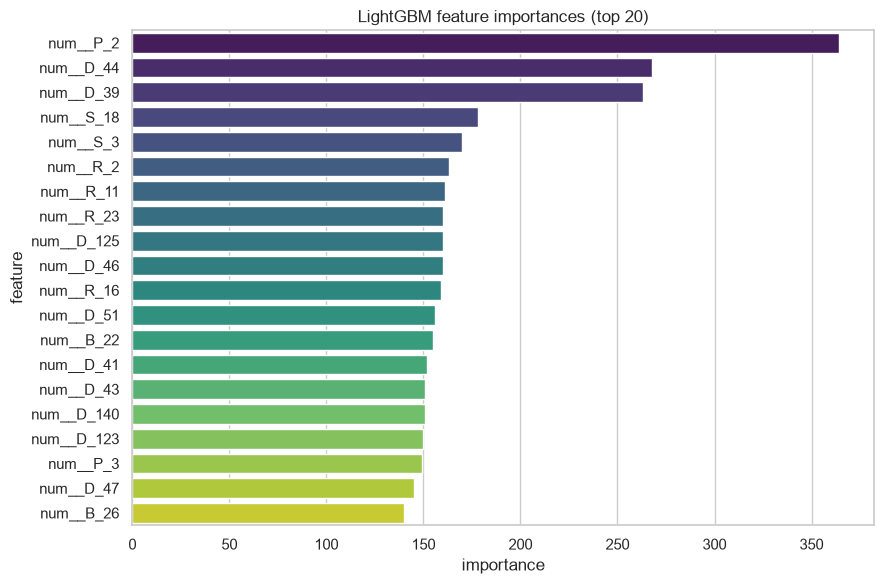

,feature,importance
0,num__P_2,364
9,num__D_44,268
1,num__D_39,263
92,num__S_18,178
5,num__S_3,170
13,num__R_2,163
79,num__R_11,161
106,num__R_23,160
144,num__D_125,160
14,num__D_46,160


In [32]:
lgbm_importance = pd.DataFrame({"feature": tree_feature_names, "importance": lgbm.feature_importances_}
                                ).sort_values("importance", ascending=False).head(20)
plt.figure(figsize=(9, 6))
sns.barplot(data=lgbm_importance, x="importance", y="feature", palette="viridis")
plt.title("LightGBM feature importances (top 20)")
plt.tight_layout()
plt.show()
lgbm_importance


### Hyperparameter tuning with `RandomizedSearchCV`

Fit the search on the training data and compare the selected model on the held-out partition.

In [33]:
lgbm_param_dist = {'n_estimators': [500], 'num_leaves': [15, 31], 'learning_rate': [0.03, 0.05]}


lgbm_search = RandomizedSearchCV(
    LGBMClassifier(subsample=0.8, colsample_bytree=0.8, min_child_samples=20,
                   random_state=RANDOM_STATE, n_jobs=2, verbose=-1),
    param_distributions=lgbm_param_dist, n_iter=2, cv=skf3, scoring="roc_auc",
    n_jobs=2, random_state=RANDOM_STATE,
)
lgbm_search.fit(X_train_enc, y_train)
print(f"Best params: {lgbm_search.best_params_}")
print(f"Best CV ROC-AUC: {lgbm_search.best_score_:.4f}")


/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Best params: {'num_leaves': 31, 'n_estimators': 500, 'learning_rate': 0.05}
Best CV ROC-AUC: 0.9405


In [34]:
y_proba_lgbm_tuned = lgbm_search.best_estimator_.predict_proba(X_test_enc)[:, 1]
evaluate("LightGBM (tuned)", y_test, y_proba_lgbm_tuned)


LightGBM (tuned)      ROC_AUC=0.9582  F1=0.7836  Precision=0.8075  Recall=0.7611


/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


{'ROC_AUC': 0.9581564274387436,
 'Accuracy': 0.8965141612200436,
 'Precision': 0.8075117370892019,
 'Recall': 0.7610619469026548,
 'F1': 0.7835990888382688,
 'LogLoss': 0.3360604026079515}

## 12. Head-to-head comparison


In [35]:
results_df = pd.DataFrame(results).T.sort_values("ROC_AUC", ascending=False)
results_df


,ROC_AUC,Accuracy,Precision,Recall,F1,LogLoss
RandomForest,0.962706,0.908497,0.828704,0.792035,0.809955,0.239272
CatBoost,0.962293,0.909586,0.820628,0.809735,0.815145,0.216058
RandomForest (tuned),0.962293,0.909586,0.829493,0.796460,0.812641,0.240618
LogReg (L2),0.960816,0.905229,0.835749,0.765487,0.799076,0.225328
XGBoost (tuned),0.959007,0.901961,0.811927,0.783186,0.797297,0.227263
CatBoost (tuned),0.958681,0.896514,0.804651,0.765487,0.784580,0.225942
LightGBM,0.958156,0.896514,0.807512,0.761062,0.783599,0.336060
LightGBM (tuned),0.958156,0.896514,0.807512,0.761062,0.783599,0.336060
XGBoost,0.958118,0.898693,0.812207,0.765487,0.788155,0.244573
LogReg (ElasticNet),0.956935,0.903050,0.840796,0.747788,0.791569,0.244967


/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98039/1082542411.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=results_df.loc[order, "ROC_AUC"], y=order, palette="viridis", ax=axes[0])


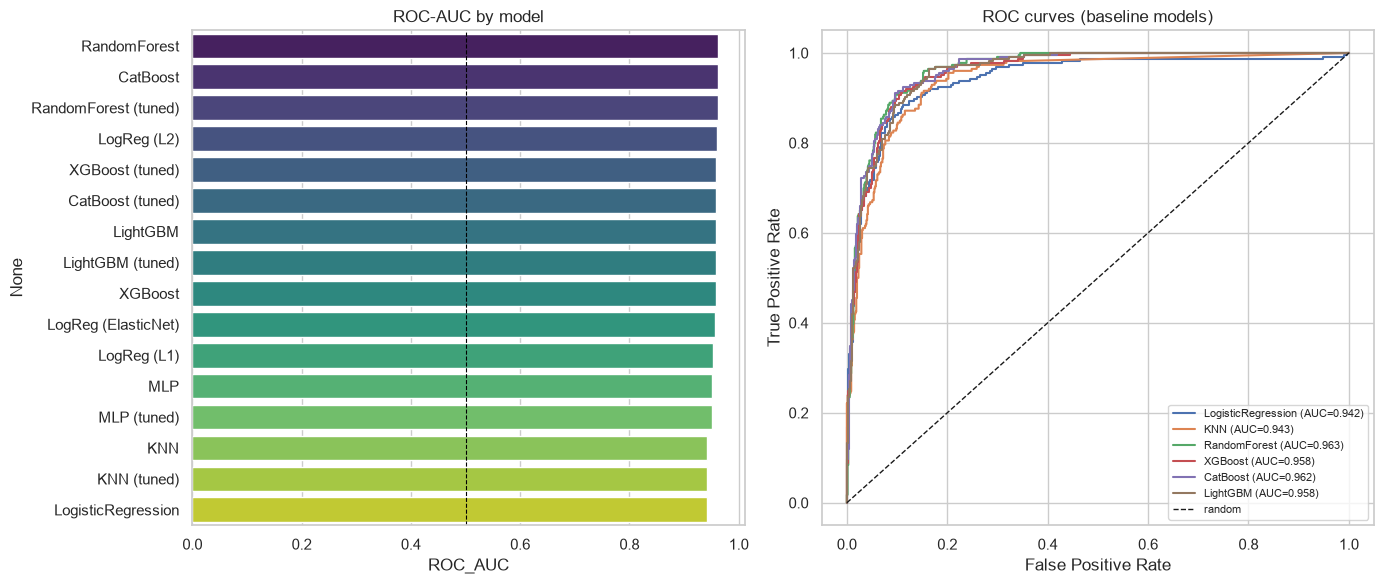

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
order = results_df.index
sns.barplot(x=results_df.loc[order, "ROC_AUC"], y=order, palette="viridis", ax=axes[0])
axes[0].set_title("ROC-AUC by model")
axes[0].axvline(0.5, color="black", linewidth=0.8, linestyle="--")

probas = {"LogisticRegression": y_proba_lr, "KNN": y_proba_knn, "RandomForest": y_proba_rf,
          "XGBoost": y_proba_xgb, "CatBoost": y_proba_cat, "LightGBM": y_proba_lgbm}
for name, p in probas.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[1].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, p):.3f})")
axes[1].plot([0, 1], [0, 1], "k--", linewidth=1, label="random")
axes[1].set_xlabel("False Positive Rate"); axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("ROC curves (baseline models)")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()


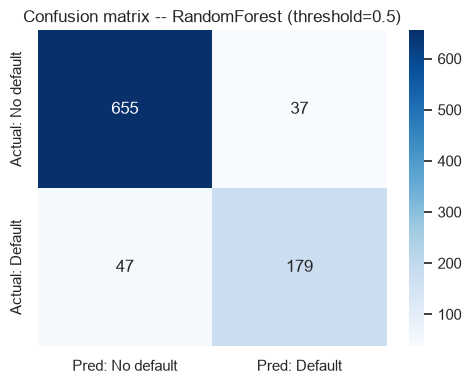

In [37]:
best_model_name = results_df.index[0]
best_proba = {**probas, "MLP": y_proba_mlp, "MLP (tuned)": y_proba_mlp_tuned,
              "RandomForest (tuned)": y_proba_rf_tuned, "XGBoost (tuned)": y_proba_xgb_tuned,
              "CatBoost (tuned)": y_proba_cat_tuned, "LightGBM (tuned)": y_proba_lgbm_tuned}[best_model_name]

cm = confusion_matrix(y_test, (best_proba >= 0.5).astype(int))
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Pred: No default", "Pred: Default"],
            yticklabels=["Actual: No default", "Actual: Default"])
plt.title(f"Confusion matrix -- {best_model_name} (threshold=0.5)")
plt.tight_layout()
plt.show()


## 13. Stacking

Combine Random Forest, XGBoost and LightGBM with a linear meta-model. The meta-model learns from out-of-fold predictions within the training partition. Compare the resulting ensemble with the individual models on the held-out partition.

In [38]:
from sklearn.ensemble import StackingClassifier

stack = StackingClassifier(
    estimators=[("forest", rf), ("xgboost", xgb), ("lightgbm", lgbm)],
    final_estimator=LogisticRegression(C=1.0, max_iter=2000, random_state=RANDOM_STATE),
    cv=2,
    n_jobs=2,
)
stack.fit(X_train_scaled, y_train)
y_proba_stack = stack.predict_proba(X_test_scaled)[:, 1]
evaluate("Stacking", y_test, y_proba_stack)


/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Stacking              ROC_AUC=0.9626  F1=0.8063  Precision=0.8211  Recall=0.7920


{'ROC_AUC': 0.9625620236329223,
 'Accuracy': 0.906318082788671,
 'Precision': 0.8211009174311926,
 'Recall': 0.7920353982300885,
 'F1': 0.8063063063063063,
 'LogLoss': 0.22549276705742724}

## 14. Conclusion

Use the measured comparison to discuss accuracy, interpretability and training cost. Regularized linear models are useful references for correlated inputs. KNN depends on the distance representation. MLP needs scaling and optimization checks. Tree ensembles capture nonlinear interactions, and stacking adds a meta-model trained on out-of-fold predictions.

Report the best measured result together with its metric and validation design. Inspect errors within important target ranges or groups before choosing a model for a new population.

In [39]:
final_results = pd.DataFrame(results).T.sort_values('ROC_AUC', ascending=False)
print("Results from this run")
display(final_results)


Results from this run


,ROC_AUC,Accuracy,Precision,Recall,F1,LogLoss
RandomForest,0.962706,0.908497,0.828704,0.792035,0.809955,0.239272
Stacking,0.962562,0.906318,0.821101,0.792035,0.806306,0.225493
CatBoost,0.962293,0.909586,0.820628,0.809735,0.815145,0.216058
RandomForest (tuned),0.962293,0.909586,0.829493,0.796460,0.812641,0.240618
LogReg (L2),0.960816,0.905229,0.835749,0.765487,0.799076,0.225328
XGBoost (tuned),0.959007,0.901961,0.811927,0.783186,0.797297,0.227263
CatBoost (tuned),0.958681,0.896514,0.804651,0.765487,0.784580,0.225942
LightGBM,0.958156,0.896514,0.807512,0.761062,0.783599,0.336060
LightGBM (tuned),0.958156,0.896514,0.807512,0.761062,0.783599,0.336060
XGBoost,0.958118,0.898693,0.812207,0.765487,0.788155,0.244573
